# 01 · PaySim EDA: where does fraud live?

**Question:** A Malaysian e-wallet fraud team wants to score transactions *before* they are authorised. What does fraud look like in PaySim, and which columns are safe to use at decision time?

PaySim is a synthetic simulator of a mobile-money service (6.36M transactions, 744 hourly steps ≈ 31 days). It is synthetic, so every pattern below is a property of the simulator first and of real fraud second.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.float_format", "{:,.4f}".format)
df = pd.read_parquet("../data/raw/paysim.parquet")
print(f"{len(df):,} rows, {df.isFraud.sum():,} fraud ({df.isFraud.mean():.3%})")
df.head()

6,362,620 rows, 8,213 fraud (0.129%)


,step,oldbalanceOrg,amount,isFraud,nameOrig,newbalanceDest,type,newbalanceOrig,isFlaggedFraud,nameDest,oldbalanceDest
0,1,"170,136.0000","9,839.6400",0,C1231006815,0.0000,PAYMENT,"160,296.3600",0,M1979787155,0.0000
1,1,"21,249.0000","1,864.2800",0,C1666544295,0.0000,PAYMENT,"19,384.7200",0,M2044282225,0.0000
2,1,181.0000,181.0000,1,C1305486145,0.0000,TRANSFER,0.0000,0,C553264065,0.0000
3,1,181.0000,181.0000,1,C840083671,0.0000,CASH_OUT,0.0000,0,C38997010,"21,182.0000"
4,1,"41,554.0000","11,668.1400",0,C2048537720,0.0000,PAYMENT,"29,885.8600",0,M1230701703,0.0000


## 1. Fraud rate by transaction type
**Finding:** fraud only ever happens in `TRANSFER` and `CASH_OUT`. CASH_IN, PAYMENT and DEBIT have zero fraud in 4.2M rows.

**Why it matters:** we train only on those two types (2.77M rows, fraud rate ~0.30%) and the API short-circuits the other three to *allow*. A model trained on all types would spend capacity learning "PAYMENT is safe".

,transactions,fraud,fraud_rate
type,,,
CASH_IN,1399284,0,0.0000
CASH_OUT,2237500,4116,0.0018
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000
TRANSFER,532909,4097,0.0077


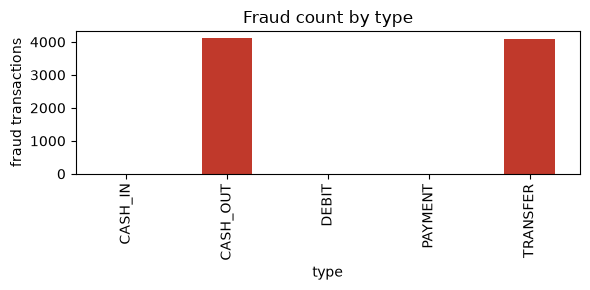

In [2]:
by_type = df.groupby("type").isFraud.agg(transactions="count", fraud="sum", fraud_rate="mean")
display(by_type)
ax = by_type["fraud"].plot.bar(color="#c0392b", figsize=(6,3), title="Fraud count by type"); ax.set_ylabel("fraud transactions"); plt.tight_layout()

## 2. Amounts
**Finding:** fraud amounts are much larger (median ~441k vs ~170k for legit TRANSFER/CASH_OUT), and 287 fraud rows sit exactly at the 10,000,000 cap: the simulator splits large thefts into 10M chunks.

**Why it matters:** amount is useful, but the 10M cap is a simulator quirk, not something to sell as an insight.

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"2,762,196.0000","314,115.4962","877,144.1496",0.0100,"82,908.2325","171,034.4600","305,994.1850","92,445,516.6400"
1,"8,213.0000","1,467,967.2991","2,404,252.9472",0.0000,"127,091.3300","441,423.4400","1,517,771.4800","10,000,000.0000"


fraud rows at 10M cap: 287


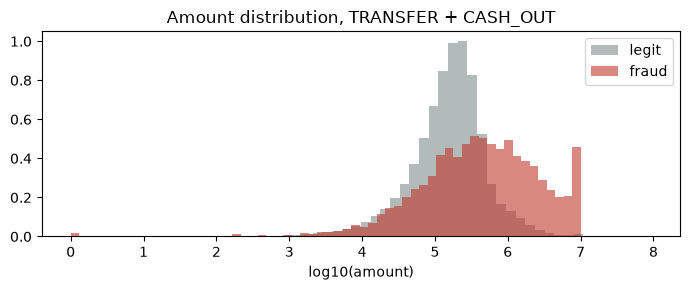

In [3]:
tc = df[df.type.isin(["TRANSFER","CASH_OUT"])].copy()
display(tc.groupby("isFraud").amount.describe())
fig, ax = plt.subplots(figsize=(7,3))
for lab, c in [(0,"#7f8c8d"),(1,"#c0392b")]:
    ax.hist(np.log10(tc.loc[tc.isFraud==lab,"amount"]+1), bins=60, alpha=.6, density=True, color=c, label=["legit","fraud"][lab])
ax.set_xlabel("log10(amount)"); ax.legend(); ax.set_title("Amount distribution, TRANSFER + CASH_OUT"); plt.tight_layout()
print("fraud rows at 10M cap:", (tc[tc.isFraud==1].amount==1e7).sum())

## 3. Balance anomalies
**Finding:** in **97.6%** of fraud the amount equals the sender's entire balance (account emptied), against essentially **0%** of legit transactions. Fraud also usually lands in a receiver account with a zero balance (65% vs 14%).

**Why it matters:** "account drained" is the single strongest signal, and it uses only pre-transaction information. But it is how PaySim's fraud agent is programmed, so real-world performance would be far lower. The modelling notebook runs an ablation without it.

In [4]:
tc["drains"] = (tc.oldbalanceOrg>0) & ((tc.amount-tc.oldbalanceOrg).abs()<0.01)
tc["dest_zero"] = tc.oldbalanceDest==0
tc["orig_zero"] = tc.oldbalanceOrg==0
tc.groupby("isFraud")[["drains","dest_zero","orig_zero"]].mean().rename(index={0:"legit",1:"fraud"})

,drains,dest_zero,orig_zero
isFraud,,,
legit,0.0000,0.1390,0.4737
fraud,0.9763,0.6515,0.0050


## 4. Time of day
**Finding:** legit traffic follows a daily cycle (almost nothing 02:00-07:00), while fraud is spread flat across all 24 hours. So the fraud *rate* at night is many times higher.

Also, legit volume collapses after day 17 while fraud stays constant (~260/day). That is a simulator artifact; it is why we use a stratified random split, not a time split, and only use hour-of-day (not absolute step) as a feature.

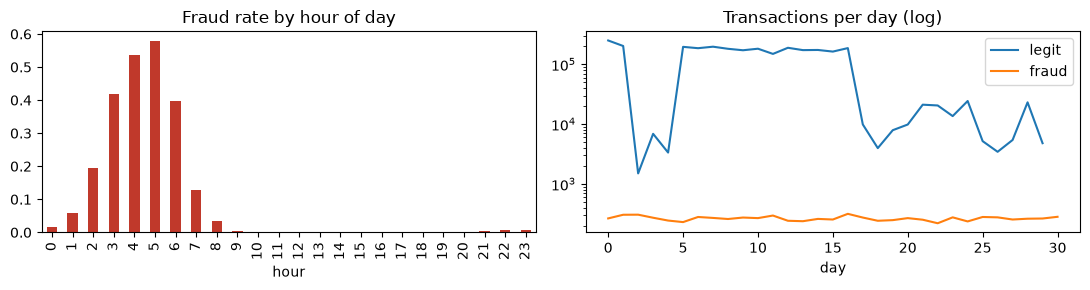

In [5]:
tc["hour"] = tc.step % 24; tc["day"] = tc.step // 24
fig, axes = plt.subplots(1,2, figsize=(11,3))
tc.groupby("hour").isFraud.mean().plot.bar(ax=axes[0], color="#c0392b", title="Fraud rate by hour of day")
tc.groupby(["day","isFraud"]).size().unstack().plot(ax=axes[1], logy=True, title="Transactions per day (log)")
axes[1].legend(["legit","fraud"]); plt.tight_layout()

## 5. Leakage check: what we dropped and why
| Column | Decision | Reason |
|---|---|---|
| `newbalanceOrig`, `newbalanceDest` | **dropped** | Post-transaction balances. A pre-authorisation API cannot know them. In PaySim they are also inconsistent for legit rows (90% of legit TRANSFER/CASH_OUT have `old - amount ≠ new`, fraud ~0.5%), so the popular "balance error" feature is a near-perfect *simulator* leak. |
| `isFlaggedFraud` | **dropped** | Output of PaySim's own rule (transfers > 200k). Fires on only 16 rows, all fraud. It is a label-derived rule, not an input. |
| `nameOrig`, `nameDest` | **dropped** | Account IDs. No sender repeats among fraud, so no usable history; IDs would just be memorised. |
| `step` | **transformed** | Only hour-of-day is kept; absolute step would encode the day-17 volume collapse. |
| `type`, `amount`, `oldbalanceOrg`, `oldbalanceDest` | **kept** | Known before authorisation. |

In [6]:
err = (tc.oldbalanceOrg - tc.amount - tc.newbalanceOrig).abs() > 1
print("share of rows where sender balance does not reconcile:"); print(err.groupby(tc.isFraud).mean().rename({0:"legit",1:"fraud"}))
print(); print("isFlaggedFraud:"); print(pd.crosstab(df.isFlaggedFraud, df.isFraud))

share of rows where sender balance does not reconcile:
isFraud
legit   0.9010
fraud   0.0055
dtype: float64

isFlaggedFraud:


isFraud               0     1
isFlaggedFraud               
0               6354407  8197
1                     0    16


## Takeaways
1. Score only TRANSFER and CASH_OUT; base rate ~0.30%, so accuracy is meaningless (99.7% by predicting "legit") and we use PR-AUC.
2. Strongest honest signals: account drained, receiver balance zero, night-time, large amount.
3. Dropped post-transaction balances, the rule flag and IDs. Features live in `src/fraud/features.py`, shared by training and the API.